# Hybrid LinearSVC + Naive Bayes

Train and evaluate a hybrid classifier that combines calibrated LinearSVC and Gaussian Naive Bayes on the cat-inclusive dataset.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

from schema_utils import detect_feature_columns, build_feature_matrix
print('Environment ready.')


Environment ready.


In [2]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train_cat.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test_cat.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
feature_cols = schema['classic_feature_cols']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))


Train size: 1661 Test size: 483
Train balance: label
human      0.493076
nothing    0.338350
cat        0.168573
Name: proportion, dtype: float64
Test balance: label
human      0.432712
nothing    0.422360
cat        0.144928
Name: proportion, dtype: float64


In [3]:
# 3-4. Features + Labels (pre-split train/test, train-only fit)
import numpy as np
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
print('Train shape:', X_train_all.shape, 'Test shape:', X_test_all.shape)
print('Classes:', list(le.classes_))


Train shape: (1661, 46) Test shape: (483, 46)
Classes: ['cat', 'human', 'nothing']


In [4]:
# 5. Hybrid classifier: calibrated LinearSVC + GaussianNB
from typing import Optional
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB

class HybridSVCNB:
    """
    Combine calibrated LinearSVC probabilities with GaussianNB probabilities via weighted average.
    - LinearSVC is scaled and calibrated (sigmoid) to produce probabilities.
    - GaussianNB is trained on raw features.
    - Final probabilities: p = w_svc * p_svc + w_nb * p_nb
    - Optional confidence threshold to assign 'nothing' when uncertain.
    """
    def __init__(self, w_svc: float = 0.6, w_nb: float = 0.4, reject_threshold: Optional[float] = None,
                 svc_C: float = 0.01, svc_class_weight: Optional[dict] = 'balanced', random_state: int = 42):
        self.w_svc = w_svc
        self.w_nb = w_nb
        self.reject_threshold = reject_threshold
        self.svc_C = svc_C
        self.svc_class_weight = svc_class_weight
        self.random_state = random_state
        self.scaler = StandardScaler()
        self.svc = LinearSVC(C=self.svc_C, class_weight=self.svc_class_weight, random_state=self.random_state)
        self.cal_svc = None
        self.nb = GaussianNB()
        self.classes_ = None
        self.idx_nothing = None

    def fit(self, X_raw: np.ndarray, y: np.ndarray, classes_: np.ndarray):
        self.classes_ = np.array(classes_)
        try:
            self.idx_nothing = int(np.where(self.classes_ == 'nothing')[0][0])
        except Exception:
            self.idx_nothing = None
        X_scaled = self.scaler.fit_transform(X_raw)
        self.cal_svc = CalibratedClassifierCV(estimator=self.svc, method='sigmoid', cv=3)
        self.cal_svc.fit(X_scaled, y)
        self.nb.fit(X_raw, y)
        return self

    def predict_proba(self, X_raw: np.ndarray) -> np.ndarray:
        X_scaled = self.scaler.transform(X_raw)
        p_svc = self.cal_svc.predict_proba(X_scaled)
        p_nb = self.nb.predict_proba(X_raw)
        if p_svc.shape != p_nb.shape:
            raise ValueError(f'Shape mismatch: SVC {p_svc.shape} vs NB {p_nb.shape}')
        p = self.w_svc * p_svc + self.w_nb * p_nb
        p = p / np.clip(np.sum(p, axis=1, keepdims=True), 1e-9, None)
        return p

    def predict(self, X_raw: np.ndarray) -> np.ndarray:
        p = self.predict_proba(X_raw)
        max_conf = np.max(p, axis=1)
        labels = np.argmax(p, axis=1)
        if self.reject_threshold is not None and self.idx_nothing is not None:
            labels = np.where(max_conf >= self.reject_threshold, labels, self.idx_nothing)
        return labels


In [12]:
# 6. Train + Evaluate Hybrid
hybrid = HybridSVCNB(w_svc=0.6, w_nb=0.4, reject_threshold=0.6, svc_C=0.01, svc_class_weight='balanced', random_state=42)
hybrid.fit(X_train_all, y_train, le.classes_)
y_pred = hybrid.predict(X_test_all)
test_accuracy = accuracy_score(y_test, y_pred)
print('Hybrid test accuracy:', round(test_accuracy, 4))
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:', cm)
print('Classification report:', classification_report(y_test, y_pred, target_names=list(le.classes_)))
# Quick cat recall check
if 'cat' in le.classes_:
    cat_idx = list(le.classes_).index('cat')
    cat_support = int((y_test == cat_idx).sum())
    cat_tp = int(((y_test == cat_idx) & (y_pred == cat_idx)).sum())
    cat_recall = (cat_tp / cat_support) if cat_support > 0 else float('nan')
    print(f'Cat support: {cat_support}, Cat recall: {cat_recall:.3f}')


Hybrid test accuracy: 0.971
Confusion matrix: [[ 70   0   0]
 [  0 195  14]
 [  0   0 204]]
Classification report:               precision    recall  f1-score   support

         cat       1.00      1.00      1.00        70
       human       1.00      0.93      0.97       209
     nothing       0.94      1.00      0.97       204

    accuracy                           0.97       483
   macro avg       0.98      0.98      0.98       483
weighted avg       0.97      0.97      0.97       483

Cat support: 70, Cat recall: 1.000


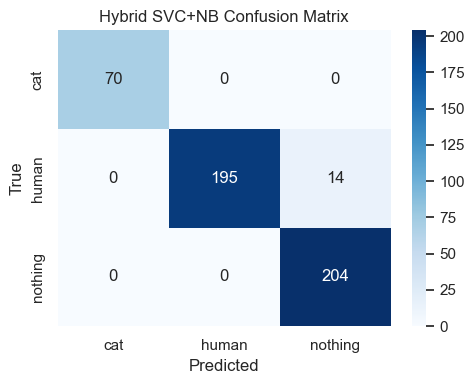

In [13]:
# 7. Confusion Matrix - Visualize mistakes
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Hybrid SVC+NB Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()


In [ ]:
# 8. Save model + meta
os.makedirs(os.path.join('..','models'), exist_ok=True)
model_path = os.path.join('..','models','hybrid_svc_nb_cat.pkl')
joblib.dump({'model': hybrid, 'label_encoder': le, 'feature_cols': feature_cols}, model_path)
print('Saved to', model_path)
meta = {
    'classes': list(le.classes_),
    'weights': {'svc': hybrid.w_svc, 'nb': hybrid.w_nb},
    'reject_threshold': hybrid.reject_threshold,
    'svc_C': hybrid.svc_C,
    'svc_class_weight': hybrid.svc_class_weight,
    'test_accuracy': float(test_accuracy),
    'confusion_matrix': cm.tolist(),
    'feature_cols': feature_cols,
    'dataset_train': 'datasets/training_data_train_cat.csv',
    'dataset_test': 'datasets/training_data_test_cat.csv',
}
meta_path = os.path.join('..','models','hybrid_svc_nb_cat_meta.json')
with open(meta_path, 'w') as f:
    import json
    json.dump(meta, f, indent=2)
print('Saved meta to', meta_path)
